# 01: Cleaning and EDA

Goal: load the Olist tables from MySQL, check them against the SQL results, clean them
and build one analysis table. Decisions from the SQL phase: customers are identified by
customer_unique_id, one review per order (the latest), revenue = price + freight on delivered orders.

In [1]:
import os

import pandas as pd
from dotenv import find_dotenv, load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

load_dotenv(find_dotenv(usecwd=True))  # searches upward from the notebook folder for .env

url = URL.create(
    drivername="mysql+pymysql",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT", "3306")),
    database=os.getenv("DB_NAME"),
)
engine = create_engine(url)

In [2]:
expected = {
    "customers": 99441, "orders": 99441, "order_items": 112650,
    "order_payments": 103886, "order_reviews": 99224,
    "products": 32951, "sellers": 3095, "product_category_translation": 71,
}

dfs = {}
with engine.connect() as conn:
    for table, n_expected in expected.items():
        dfs[table] = pd.read_sql(text(f"SELECT * FROM {table}"), conn)
        n = len(dfs[table])
        print(f"{table:32} rows: {n:>9,} | {'OK' if n == n_expected else 'MISMATCH'}")

customers                        rows:    99,441 | OK
orders                           rows:    99,441 | OK
order_items                      rows:   112,650 | OK
order_payments                   rows:   103,886 | OK
order_reviews                    rows:    99,224 | OK
products                         rows:    32,951 | OK
sellers                          rows:     3,095 | OK
product_category_translation     rows:        71 | OK


In [3]:
dfs["orders"].dtypes

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

In [4]:
orders = dfs["orders"]
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [5]:
print("duplicate order_id:", orders["order_id"].duplicated().sum())
print("duplicate customer_id:", orders["customer_id"].duplicated().sum())
print("distinct customer_unique_id:", dfs["customers"]["customer_unique_id"].nunique(),
      "of", len(dfs["customers"]), "customer rows")

duplicate order_id: 0
duplicate customer_id: 0
distinct customer_unique_id: 96096 of 99441 customer rows


**Checks (orders):** no duplicate order_id; customer_id is unique per order, so repeat buyers
are identified with customer_unique_id; delivery date is missing for orders not yet delivered.

**Decision (reviews):** 547 orders have more than one review. Keep the latest per order
(review_creation_date, then review_answer_timestamp), and join reviews on order_id only.
Orders have missing approved and carrier dates in some rows (160 and 1,783); these columns
are not used in the analysis and the reason was not investigated.

In [6]:
reviews_latest = (
    dfs["order_reviews"]
    .sort_values(["order_id", "review_creation_date", "review_answer_timestamp"],
                 ascending=[True, False, False])
    .drop_duplicates(subset="order_id", keep="first")
    [["order_id", "review_score"]]
)

print("rows:", len(reviews_latest))
print("one row per order:", reviews_latest["order_id"].is_unique)

rows: 98673
one row per order: True


In [7]:
orders_enriched = (
    orders
    .merge(dfs["customers"][["customer_id", "customer_unique_id", "customer_state"]],
           on="customer_id", how="left")
    .merge(reviews_latest, on="order_id", how="left")
)

print("rows:", len(orders_enriched))
print("one row per order:", orders_enriched["order_id"].is_unique)
print("orders without a review:", orders_enriched["review_score"].isna().sum())

rows: 99441
one row per order: True
orders without a review: 768


In [8]:
deliv = orders_enriched["order_delivered_customer_date"]
purch = orders_enriched["order_purchase_timestamp"]
est = orders_enriched["order_estimated_delivery_date"]

# whole calendar days, same as MySQL DATEDIFF
orders_enriched["delivery_days"] = (deliv.dt.normalize() - purch.dt.normalize()).dt.days
orders_enriched["delay_days"] = (deliv.dt.normalize() - est.dt.normalize()).dt.days

# 1.0 = late, 0.0 = not late, NaN = no delivery date (so we never call an undelivered order "on time")
orders_enriched["is_late"] = (deliv > est).astype("float").where(deliv.notna())

d = orders_enriched[(orders_enriched["order_status"] == "delivered") & deliv.notna()]
print("delivered with a date:", len(d))
print("avg delivery days:", round(d["delivery_days"].mean(), 1))
print("late share %:", round(100 * d["is_late"].mean(), 1))

delivered with a date: 96470
avg delivery days: 12.5
late share %: 8.1


In [9]:
items_per_order = (
    dfs["order_items"]
    .assign(item_total=lambda x: x["price"] + x["freight_value"])
    .groupby("order_id", as_index=False)
    .agg(order_value=("item_total", "sum"), n_items=("order_item_id", "count"))
)

orders_enriched = orders_enriched.merge(items_per_order, on="order_id", how="left")

delivered = orders_enriched[orders_enriched["order_status"] == "delivered"]
print("rows:", len(orders_enriched), "| one row per order:", orders_enriched["order_id"].is_unique)
print("delivered revenue:", round(delivered["order_value"].sum(), 2))
print("delivered avg order value:", round(delivered["order_value"].mean(), 2))
print("orders without items:", orders_enriched["order_value"].isna().sum())

rows: 99441 | one row per order: True
delivered revenue: 15419773.75
delivered avg order value: 159.83
orders without items: 775


In [10]:
no_items = orders_enriched[orders_enriched["order_value"].isna()]
print(no_items["order_status"].value_counts())
print("total:", len(no_items))

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64
total: 775


**Decision (order value):** order_value = sum of price + freight_value per order. 775 orders
have no items (unavailable 603, canceled 164, created 5, invoiced 2, shipped 1) and none is
delivered. Their order_value stays empty (NaN), not 0, so averages are never pulled down.
Revenue and order-value analysis uses delivered orders only.

In [11]:
valid = orders_enriched[~orders_enriched["order_status"].isin(["canceled", "unavailable"])].copy()
valid = valid.sort_values(["customer_unique_id", "order_purchase_timestamp"])

valid["order_number"] = valid.groupby("customer_unique_id").cumcount() + 1
valid["person_total_orders"] = valid.groupby("customer_unique_id")["order_id"].transform("count")

orders_enriched = orders_enriched.merge(
    valid[["order_id", "order_number", "person_total_orders"]], on="order_id", how="left")

people = valid.groupby("customer_unique_id")["order_id"].count()
print("rows:", len(orders_enriched), "| one row per order:", orders_enriched["order_id"].is_unique)
print("orders kept:", len(valid))
print("people:", len(people))
print("people with 2+ orders:", (people > 1).sum(), f"({100 * (people > 1).mean():.2f}%)")

rows: 99441 | one row per order: True
orders kept: 98207
people: 94990
people with 2+ orders: 2888 (3.04%)


## Analysis table: orders_enriched (one row per order)

Built from orders + customers + latest review per order + item totals. Added columns:
customer_unique_id, customer_state, review_score (latest per order), delivery_days, delay_days,
is_late (NaN when not delivered), order_value and n_items (NaN for orders without items),
order_number and person_total_orders (canceled and unavailable orders excluded, so NaN for them).
All counts were checked against the SQL results.

In [12]:
from pathlib import Path

out_dir = Path(find_dotenv(usecwd=True)).parent / "data" / "processed"
out_dir.mkdir(parents=True, exist_ok=True)
orders_enriched.to_csv(out_dir / "orders_enriched.csv", index=False)

print("saved to:", out_dir / "orders_enriched.csv")
print("shape:", orders_enriched.shape)

saved to: d:\VS\Olist Project\olist-retention-analytics\data\processed\orders_enriched.csv
shape: (99441, 18)


23 months | 96478 orders | 15419773.75


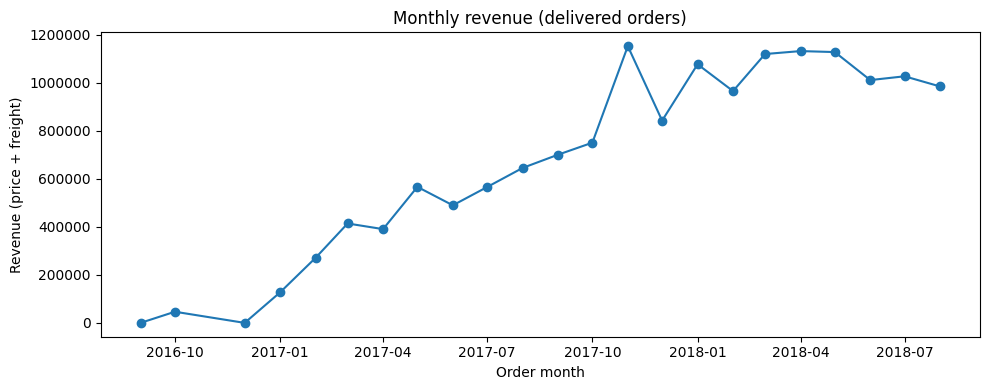

In [13]:
import matplotlib.pyplot as plt

delivered = orders_enriched[orders_enriched["order_status"] == "delivered"].copy()
delivered["order_month"] = delivered["order_purchase_timestamp"].dt.to_period("M")

monthly = (delivered.groupby("order_month")
           .agg(orders=("order_id", "count"), revenue=("order_value", "sum"))
           .reset_index())
monthly["order_month"] = monthly["order_month"].dt.to_timestamp()

print(len(monthly), "months |", monthly["orders"].sum(), "orders |", round(monthly["revenue"].sum(), 2))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly["order_month"], monthly["revenue"], marker="o")
ax.set_title("Monthly revenue (delivered orders)")
ax.set_xlabel("Order month")
ax.set_ylabel("Revenue (price + freight)")
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

**Insight:** Monthly revenue grew from about 127,000 in January 2017 to a peak of 1.15 million in
November 2017, then stayed between roughly 0.97 and 1.13 million a month through August 2018, so
growth stalled in 2018. (There are no orders in November 2016, so the line there is a gap, not a low month.)

orders: 96470
count    96470.0
mean        12.5
std          9.6
min          0.0
25%          7.0
50%         10.0
75%         16.0
max        210.0
Name: delivery_days, dtype: float64
orders slower than 60 days (cut off from the chart): 298


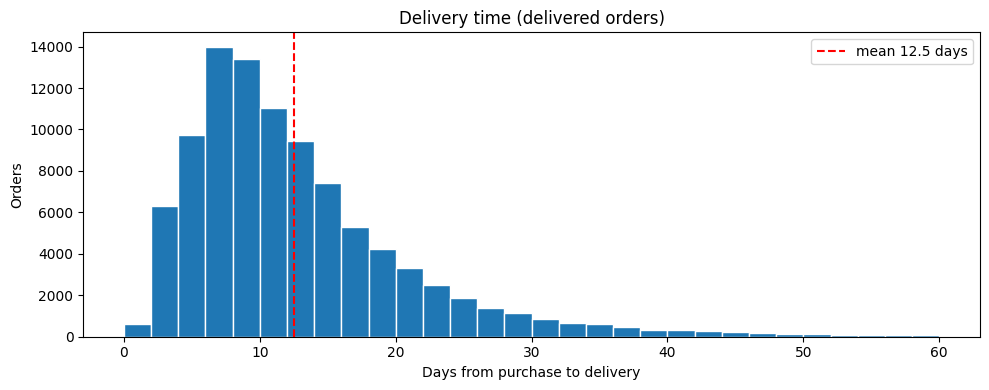

In [14]:
d = orders_enriched[(orders_enriched["order_status"] == "delivered")
                    & orders_enriched["delivery_days"].notna()]

print("orders:", len(d))
print(d["delivery_days"].describe().round(1))
print("orders slower than 60 days (cut off from the chart):", (d["delivery_days"] > 60).sum())

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(d["delivery_days"], bins=range(0, 61, 2), edgecolor="white")
ax.axvline(d["delivery_days"].mean(), color="red", linestyle="--",
           label=f"mean {d['delivery_days'].mean():.1f} days")
ax.set_title("Delivery time (delivered orders)")
ax.set_xlabel("Days from purchase to delivery")
ax.set_ylabel("Orders")
ax.legend()
plt.tight_layout()
plt.show()

**Insight:** The typical delivered order arrives in 10 days (median) and 75% arrive within 16 days.
The mean is higher, 12.5 days, because a long tail of slow orders pulls it up; only 298 orders
(about 0.3%) took more than 60 days. Slow delivery here is about days elapsed, not about missing the promised date.

reviewed delivered orders: 95832
average score: 4.16
review_score
1.0     9.8
2.0     3.0
3.0     8.3
4.0    19.7
5.0    59.2
Name: proportion, dtype: float64


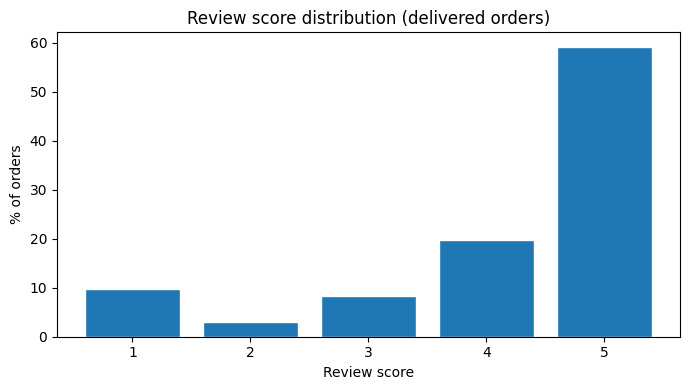

In [15]:
r = orders_enriched[(orders_enriched["order_status"] == "delivered")
                    & orders_enriched["review_score"].notna()]

print("reviewed delivered orders:", len(r))
print("average score:", round(r["review_score"].mean(), 2))
share = (r["review_score"].value_counts(normalize=True).sort_index() * 100).round(1)
print(share)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(share.index.astype(int), share.values, edgecolor="white")
ax.set_title("Review score distribution (delivered orders)")
ax.set_xlabel("Review score")
ax.set_ylabel("% of orders")
plt.tight_layout()
plt.show()

**Insight:** Reviews are strongly positive: 59.2% of delivered orders get 5 stars and 78.9% get 4 or 5,
with an average of 4.16 (95,832 reviewed orders). The low end is uneven: 1 star (9.8%) is about three
times as common as 2 stars (3.0%) and more common than 3 stars (8.3%), so unhappy customers mostly give
the lowest score. The chart does not show why; late delivery (average 2.57 stars in the SQL analysis)
is a lead to test, not a finding.

customer_state
SP    5769703.15
RJ    2055401.57
MG    1818891.67
RS     861472.79
PR     781708.80
SC     595127.78
BA     591137.81
DF     346123.35
GO     334212.35
ES     317657.93
Name: order_value, dtype: float64
top 10 share of revenue %: 87.4


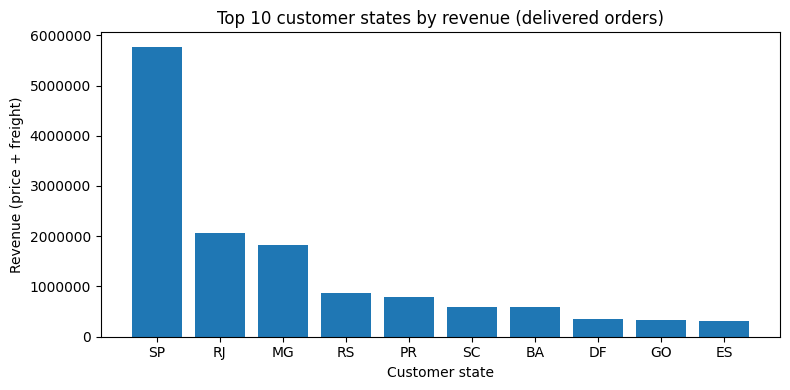

In [16]:
by_state = (delivered.groupby("customer_state")["order_value"].sum()
            .sort_values(ascending=False))
top = by_state.head(10)

print(top.round(2))
print("top 10 share of revenue %:", round(100 * top.sum() / by_state.sum(), 1))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(top.index, top.values)
ax.set_title("Top 10 customer states by revenue (delivered orders)")
ax.set_xlabel("Customer state")
ax.set_ylabel("Revenue (price + freight)")
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

**Insight:** Revenue is concentrated in a few states: São Paulo (SP) alone brings 5.77 million,
about 37% of the total and nearly three times Rio de Janeiro (RJ, 2.06 million). SP, RJ and
Minas Gerais (MG) together bring about 62.5%, and the top 10 states 87.4%. These are customer
locations, so any delivery or retention problem in these three states affects the most people.

product_category_name_english
health_beauty            1412089.53
watches_gifts            1264333.12
bed_bath_table           1225209.26
sports_leisure           1118256.91
computers_accessories    1032723.77
furniture_decor           880329.92
housewares                758392.25
cool_stuff                691680.89
auto                      669454.75
garden_tools              567145.68
Name: item_total, dtype: float64
top 10 share of revenue %: 62.4
total revenue: 15419773.75


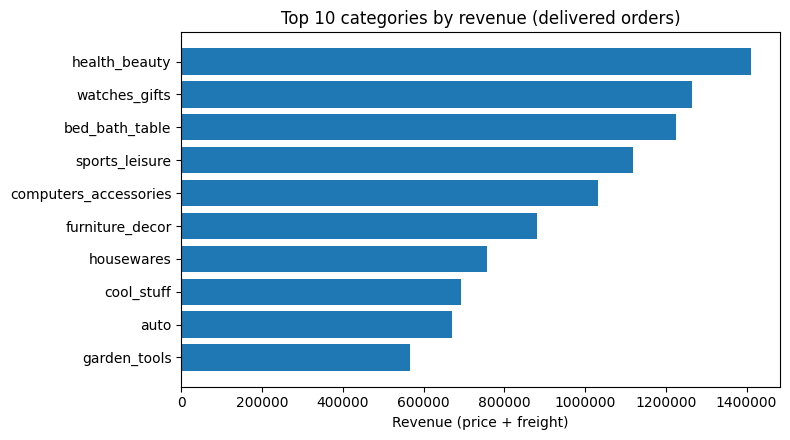

In [17]:
items = (dfs["order_items"]
         .merge(delivered[["order_id"]], on="order_id")
         .merge(dfs["products"][["product_id", "product_category_name"]], on="product_id", how="left")
         .merge(dfs["product_category_translation"], on="product_category_name", how="left"))
items["item_total"] = items["price"] + items["freight_value"]

by_cat = (items.groupby("product_category_name_english", dropna=False)["item_total"].sum()
          .sort_values(ascending=False))
top = by_cat.head(10)

print(top.round(2))
print("top 10 share of revenue %:", round(100 * top.sum() / by_cat.sum(), 1))
print("total revenue:", round(by_cat.sum(), 2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index[::-1], top.values[::-1])
ax.set_title("Top 10 categories by revenue (delivered orders)")
ax.set_xlabel("Revenue (price + freight)")
ax.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

**Insight:** Revenue is spread across many categories. The largest, health_beauty, brings 1.41 million
(about 9.2% of revenue), the top five together about 39%, and the top 10 62.4%, so no single category
dominates. The top earners are not necessarily the best at keeping customers: in the SQL analysis,
health_beauty and watches_gifts have repeat rates below the 3.04% average. That comparison is a lead
for the retention analysis, not something this chart shows.